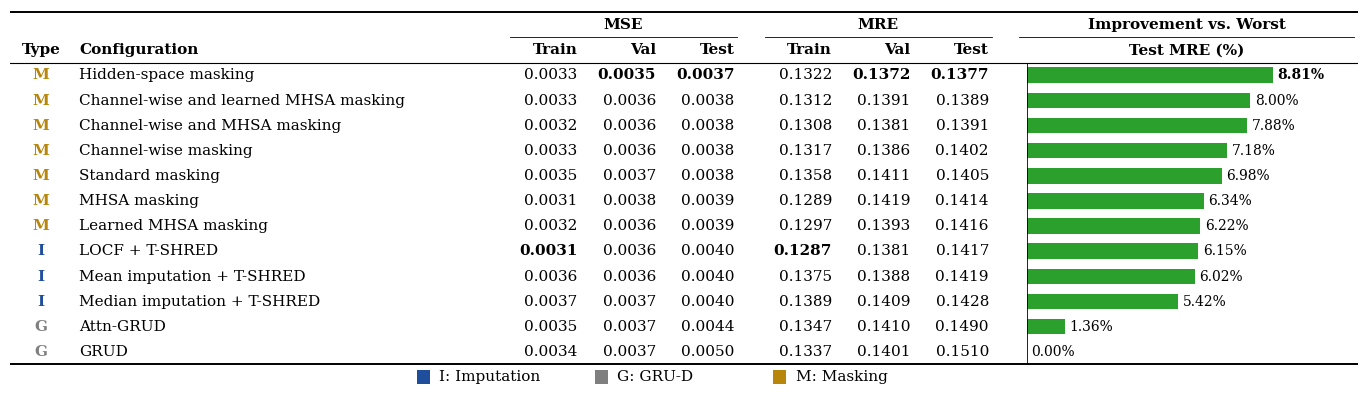

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
})

path = "outputs/RUNS/RUN4/dataframe_errors.csv"
df = pd.read_csv(path).sort_values("test-mre").reset_index(drop=True)

num_cols = ["train-mse", "val-mse", "test-mse", "train-mre", "val-mre", "test-mre"]
best = df[num_cols].min()

# ---- improvement vs worst model ----
worst_mre = df["test-mre"].max()
df["impr"] = (worst_mre - df["test-mre"]) / worst_mre * 100
best_impr = df["impr"].max()

# ---- colori per gruppo (palette da paper) ----
C_BASE  = "#000000"   # nero   -> baselines
C_IMPUT = "#1F4E9C"   # blu    -> imputation
C_MASK  = "#B8860B"   # oro    -> masking
C_GRUD  = "#7F7F7F"   # grigio -> GRU-D

GROUP_COLORS = {"0": C_BASE, "1": C_IMPUT, "2": C_GRUD, "3": C_MASK}
GROUP_LETTER = {"0": "B", "1": "I", "2": "G", "3": "M"}

# legenda: (lettera, nome, colore)
LEGEND = [
    ("I", "Imputation", C_IMPUT),
    ("G", "GRU-D",      C_GRUD),
    ("M", "Masking",    C_MASK),
]

# ---- rinomina etichette ----
# chiavi: testo originale (dopo il tag); il confronto è case-insensitive
RENAME = {
    # --- Masking (M) ---
    "masking x2 channels + MHSA learned":    "Channel-wise and learned MHSA masking",
    "masking hidden space":                  "Hidden-space masking",
    "masking x2 channels + MHSA":            "Channel-wise and MHSA masking",
    "masking":                               "Standard masking",
    "masking MHSA":                          "MHSA masking",
    "masking MHSA learned":                  "Learned MHSA masking",
    "masking x2 channels":                   "Channel-wise masking",

    # --- Imputation (I) ---
    "last-value imputation for missing sensors": "LOCF + T-SHRED",
    "LOCF for missing sensors":                  "LOCF + T-SHRED",
    "median imputation for missing sensors":     "Median imputation + T-SHRED",
    "mean imputation for missing sensors":       "Mean imputation + T-SHRED",

    # --- GRU-D (G) ---
    "GRUD":                                  "GRUD",        # TODO
    "Attn-GRUD":                             "Attn-GRUD",   # TODO

    # --- Baselines (B) ---
    "always-available stations only":             "Always-available sensors + SHRED",
    "always-available stations only transformer": "Always-available sensors + T-SHRED",
}

def _norm(s):
    """Minuscolo, spazi multipli ridotti a uno, bordi puliti."""
    return re.sub(r"\s+", " ", s).strip().lower()

RENAME_NORM = {_norm(k): v for k, v in RENAME.items()}

def rename_rest(s):
    body = s.lstrip(": ").strip()
    key = _norm(body)
    if key not in RENAME_NORM:
        print("NO MATCH:", repr(body))   # utile per aggiungere le chiavi mancanti
    return RENAME_NORM.get(key, body)

TAG_RE = re.compile(r"^\(([A-Za-z])\.(\d)(?:\.([A-Za-z0-9]+))?\)(.*)$")

def parse_label(text):
    """Ritorna (lettera, testo, colore)."""
    m = TAG_RE.match(text)
    if not m:
        return "", text, "black"
    _, group, _, rest = m.groups()
    return GROUP_LETTER.get(group, "?"), rename_rest(rest), GROUP_COLORS.get(group, "black")

# ---- font ----
fs = 11                                # dimensione base del testo
fs_small = fs - 1                      # etichette % delle barre

# ---- layout (widths in inches) ----
# colonne: 0 Type | 1 Configuration | 2-4 MSE | 5 gap | 6-8 MRE | 9 gap | 10 barre
type_col_w = 0.8
first_col_w = 5.6
num_col_w = 0.92 * 1.10     # +10%
bar_col_w = 3.4 * 1.30      # +30%
gap_w = 0.25                # spazio tra i gruppi

widths = ([type_col_w, first_col_w]
          + [num_col_w] * 3 + [gap_w]
          + [num_col_w] * 3 + [gap_w]
          + [bar_col_w])
xs = [sum(widths[:i]) for i in range(len(widths))]
total_w = sum(widths)

MSE_COLS = [2, 3, 4]
MRE_COLS = [6, 7, 8]
NUM_COLS = MSE_COLS + MRE_COLS
BAR = len(widths) - 1

row_h = 0.32
n_rows = len(df)
header_rows = 2
legend_rows = 1.0
fig_h = (n_rows + header_rows + legend_rows + 0.2) * row_h + 0.1

fig, ax = plt.subplots(figsize=(total_w, fig_h))
ax.set_xlim(0, total_w)
ax.set_ylim(n_rows + header_rows + legend_rows + 0.1, -0.1)
ax.axis("off")

pad = 0.09

def put(col, row, text, ha="left", **kw):
    if ha == "left":
        x = xs[col] + pad
    elif ha == "right":
        x = xs[col] + widths[col] - pad
    else:
        x = xs[col] + widths[col] / 2
    ax.text(x, row + 0.5, text, ha=ha, va="center", fontsize=fs, **kw)

# ---- header ----
ax.text(xs[2] + sum(widths[2:5]) / 2, 0.5, "MSE", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[6] + sum(widths[6:9]) / 2, 0.5, "MRE", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[BAR] + widths[BAR] / 2, 0.5, "Improvement vs. Worst", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.plot([xs[2] + 0.05, xs[5] - 0.05], [1, 1], color="black", lw=0.6)
ax.plot([xs[6] + 0.05, xs[9] - 0.05], [1, 1], color="black", lw=0.6)
ax.plot([xs[BAR] + 0.05, total_w - 0.05], [1, 1], color="black", lw=0.6)

put(0, 1, "Type", ha="center", fontweight="bold")
put(1, 1, "Configuration", fontweight="bold")
for col, name in zip(NUM_COLS, ["Train", "Val", "Test"] * 2):
    put(col, 1, name, ha="right", fontweight="bold")
ax.text(xs[BAR] + widths[BAR] / 2, 1.5, "Test MRE (%)", ha="center", va="center", fontsize=fs, fontweight="bold")

# ---- bar scale ----
label_w = 1.0
bx0 = xs[BAR] + 0.15
usable = widths[BAR] - 0.15 - label_w - 0.1
vmin = min(df["impr"].min(), 0.0)
vmax = max(df["impr"].max(), 1e-9)
scale = usable / (vmax - vmin)
zero_x = bx0 + (-vmin) * scale
bar_h = 0.62

# ---- body ----
for r, row in df.iterrows():
    y = r + header_rows
    letter, rest, color = parse_label(row["type"])
    put(0, y, letter, ha="center", color=color, fontweight="bold")
    put(1, y, rest)
    for col, c in zip(NUM_COLS, num_cols):
        is_best = row[c] == best[c]
        put(col, y, f"{row[c]:.4f}", ha="right", fontweight="bold" if is_best else "normal")

    v = row["impr"]
    w = v * scale
    ax.add_patch(Rectangle((zero_x if v >= 0 else zero_x + w, y + (1 - bar_h) / 2),
                           abs(w), bar_h, facecolor="#2ca02c", edgecolor="none"))

    weight = "bold" if np.isclose(v, best_impr) else "normal"
    if v >= 0:
        ax.text(zero_x + w + 0.06, y + 0.5, f"{v:.2f}%", ha="left", va="center",
                fontsize=fs_small, fontweight=weight)
    else:
        ax.text(zero_x + w - 0.06, y + 0.5, f"{v:.2f}%", ha="right", va="center",
                fontsize=fs_small, fontweight=weight)

ax.plot([zero_x, zero_x], [header_rows, n_rows + header_rows], color="black", lw=0.6)

# ---- three booktabs rules ----
ax.plot([0, total_w], [0, 0], color="black", lw=1.4)
ax.plot([0, total_w], [header_rows, header_rows], color="black", lw=0.8)
ax.plot([0, total_w], [n_rows + header_rows, n_rows + header_rows], color="black", lw=1.4)

# ---- legenda sotto la tabella ----
ly = n_rows + header_rows + legend_rows / 2
sq = 0.17
sq_h = sq / row_h
gap_marker_text = 0.12
entry_w = 2.3
x_start = (total_w - entry_w * len(LEGEND)) / 2

for i, (letter, label, color) in enumerate(LEGEND):
    x = x_start + i * entry_w
    ax.add_patch(Rectangle((x, ly - sq_h / 2), sq, sq_h, facecolor=color, edgecolor="none"))
    ax.text(x + sq + gap_marker_text, ly, f"{letter}: {label}", ha="left", va="center", fontsize=fs)

fig.savefig("ORESUND_table.png", dpi=500, bbox_inches="tight", pad_inches=0.03)
plt.show()

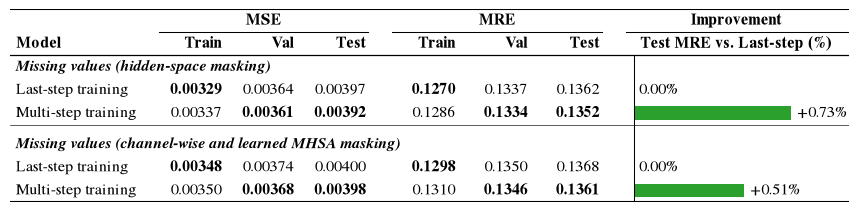

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ---------------------------------------------------------------------
# Stile: dimensioni reali da paper
# ---------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# =====================================================================
# DATI
# =====================================================================
# =====================================================================
# DATI
# =====================================================================

DATA = {
    "Missing values (hidden-space masking)": {
        "Last-step training": {
            "train_mse": 0.0032943323275479,
            "val_mse":   0.0036386988481146,
            "test_mse":  0.0039717527161019,
            "train_mre": 0.1269979436886064,
            "val_mre":   0.1337138278092827,
            "test_mre":  0.1361527702213271,
        },

        "Multi-step training": {
            "train_mse": 0.0033720868633268,
            "val_mse":   0.0036136492051507,
            "test_mse":  0.0039218359070191,
            "train_mre": 0.1285885268555618,
            "val_mre":   0.1334000497866468,
            "test_mre":  0.1351561141456865,
        },
    },

    "Missing values (channel-wise and learned MHSA masking)": {
        "Last-step training": {
            "train_mse": 0.0034814941084246,
            "val_mse":   0.0037439612160312,
            "test_mse":  0.0039998642989477,
            "train_mre": 0.1298127154119400,
            "val_mre":   0.1349657573998607,
            "test_mre":  0.1368426259604872,
        },

        "Multi-step training": {
            "train_mse": 0.0034960056810673,
            "val_mse":   0.0036790717423531,
            "test_mse":  0.0039806895756998,
            "train_mre": 0.1310221901121339,
            "val_mre":   0.1345927507630283,
            "test_mre":  0.1361403782336937,
        },
    },
}

# =====================================================================
# CONFIGURAZIONE
# =====================================================================

MSE_SCALE, MSE_DEC = 1, 5
MRE_SCALE, MRE_DEC = 1, 4

C_BAR = "#2ca02c"

# Fattore di scala globale
S = 1.5

FS = 7.5 * S

# Spazio extra dopo la linea di separazione
GAP = 0.35

KEYS = [
    "train_mse",
    "val_mse",
    "test_mse",
    "train_mre",
    "val_mre",
    "test_mre",
]

# =====================================================================
# COSTRUZIONE RIGHE
# =====================================================================

rows = []

for gi, (group, models) in enumerate(DATA.items()):

    # Separazione tra i due blocchi
    if gi > 0:
        rows.append(("gap", None))

    # Titolo del blocco
    rows.append(("title", group))

    # Baseline = Last-step training
    base = models["Last-step training"]["test_mre"]

    # Miglior valore per ogni colonna
    best = {
        k: min(model[k] for model in models.values())
        for k in KEYS
    }

    # Righe del blocco
    for name, model in models.items():

        improvement = (
            (base - model["test_mre"]) / base * 100
        )

        rows.append((
            "data",
            {
                "name": name,
                "vals": model,
                "best": best,
                "is_base": name == "Last-step training",
                "impr": improvement,
            }
        ))

# Miglior improvement complessivo
best_impr = max(
    r[1]["impr"]
    for r in rows
    if r[0] == "data"
)

# Altezza del corpo
body_h = sum(
    GAP if r[0] == "gap" else 1
    for r in rows
)

# =====================================================================
# LAYOUT
#
# Model | 3 MSE | gap | 3 MRE | gap | Improvement
# =====================================================================

nw = 0.62 * S

widths = (
    [1.25 * S] +
    [nw] * 3 +
    [0.15 * S] +
    [nw] * 3 +
    [0.15 * S] +
    [1.95 * S]
)

xs = [
    sum(widths[:i])
    for i in range(len(widths))
]

total_w = sum(widths)

NUM_COLS = [1, 2, 3, 5, 6, 7]

BAR = len(widths) - 1

# =====================================================================
# DIMENSIONI FIGURA
# =====================================================================

row_h = 0.20 * S

header_rows = 2

n_rows = body_h

fig_h = (
    n_rows + header_rows
) * row_h

fig, ax = plt.subplots(
    figsize=(total_w, fig_h)
)

ax.set_xlim(
    0,
    total_w
)

ax.set_ylim(
    n_rows + header_rows,
    0
)

ax.axis("off")

pad = 0.05 * S


# =====================================================================
# FUNZIONI DI SUPPORTO
# =====================================================================

def put(
    col,
    row,
    text,
    ha="left",
    **kw
):
    """
    Scrive testo all'interno di una cella.
    """

    x = {
        "left": xs[col] + pad,
        "right": xs[col] + widths[col] - pad,
        "center": xs[col] + widths[col] / 2,
    }[ha]

    ax.text(
        x,
        row + 0.5,
        text,
        ha=ha,
        va="center",
        fontsize=FS,
        **kw
    )


def span(c0, c1):
    """
    Centro di un gruppo di colonne.
    """

    return (
        xs[c0]
        + (
            xs[c1]
            + widths[c1]
            - xs[c0]
        ) / 2
    )


# =====================================================================
# HEADER
# =====================================================================

# ---------------- MSE ----------------

ax.text(
    span(1, 3),
    0.5,
    "MSE",
    ha="center",
    va="center",
    fontsize=FS,
    fontweight="bold",
)

ax.plot(
    [
        xs[1] + 0.03 * S,
        xs[3] + widths[3] - 0.03 * S
    ],
    [1, 1],
    color="black",
    lw=0.5 * S,
)

# ---------------- MRE ----------------

ax.text(
    span(5, 7),
    0.5,
    "MRE",
    ha="center",
    va="center",
    fontsize=FS,
    fontweight="bold",
)

ax.plot(
    [
        xs[5] + 0.03 * S,
        xs[7] + widths[7] - 0.03 * S
    ],
    [1, 1],
    color="black",
    lw=0.5 * S,
)

# ---------------- Improvement ----------------

ax.text(
    span(BAR, BAR),
    0.5,
    "Improvement",
    ha="center",
    va="center",
    fontsize=FS,
    fontweight="bold",
)

ax.plot(
    [
        xs[BAR] + 0.03 * S,
        total_w
    ],
    [1, 1],
    color="black",
    lw=0.5 * S,
)

# =====================================================================
# SECONDA RIGA HEADER
# =====================================================================

put(
    0,
    1,
    "Model",
    fontweight="bold"
)

for col, name in zip(
    NUM_COLS,
    ["Train", "Val", "Test"] * 2
):
    put(
        col,
        1,
        name,
        ha="right",
        fontweight="bold"
    )

ax.text(
    span(BAR, BAR),
    1.5,
    "Test MRE vs. Last-step (%)",
    ha="center",
    va="center",
    fontsize=FS,
    fontweight="bold",
)

# =====================================================================
# SCALA BARRE
# =====================================================================

label_w = 0.50 * S

zero_x = (
    xs[BAR]
    + 0.10 * S
)

scale = (
    widths[BAR]
    - 0.10 * S
    - label_w
) / best_impr

bar_h = 0.60

# =====================================================================
# CORPO TABELLA
# =====================================================================

y = header_rows

for kind, content in rows:

    # ---------------------------------------------------------------
    # Separatore tra blocchi
    # ---------------------------------------------------------------

    if kind == "gap":

        ax.plot(
            [0, total_w],
            [y, y],
            color="black",
            lw=0.3 * S
        )

        y += GAP

        continue

    # ---------------------------------------------------------------
    # Titolo del blocco
    # ---------------------------------------------------------------

    if kind == "title":

        ax.text(
            pad,
            y + 0.5,
            content,
            ha="left",
            va="center",
            fontsize=FS,
            fontstyle="italic",
            fontweight="bold",
        )

        y += 1

        continue

    # ---------------------------------------------------------------
    # Riga dati
    # ---------------------------------------------------------------

    r = content

    # Model
    put(
        0,
        y,
        r["name"]
    )

    # ---------------------------------------------------------------
    # Valori numerici
    # ---------------------------------------------------------------

    for col, key in zip(
        NUM_COLS,
        KEYS
    ):

        if key.endswith("mse"):
            dec = MSE_DEC
            scale_value = MSE_SCALE
        else:
            dec = MRE_DEC
            scale_value = MRE_SCALE

        value = r["vals"][key]

        is_best = (
            value == r["best"][key]
        )

        put(
            col,
            y,
            f"{value * scale_value:.{dec}f}",
            ha="right",
            fontweight=(
                "bold"
                if is_best
                else "normal"
            )
        )

    # ---------------------------------------------------------------
    # Improvement
    # ---------------------------------------------------------------

    if r["is_base"]:

        ax.text(
            zero_x + 0.04 * S,
            y + 0.5,
            "0.00%",
            ha="left",
            va="center",
            fontsize=FS,
        )

    else:

        w = r["impr"] * scale

        ax.add_patch(
            Rectangle(
                (
                    zero_x,
                    y + (1 - bar_h) / 2
                ),
                w,
                bar_h,
                facecolor=C_BAR,
                edgecolor="none",
            )
        )

        ax.text(
            zero_x + w + 0.05 * S,
            y + 0.5,
            f"+{r['impr']:.2f}%",
            ha="left",
            va="center",
            fontsize=FS,
            fontweight="normal",
        )

    y += 1


# =====================================================================
# LINEA VERTICALE IMPROVEMENT
# =====================================================================

ax.plot(
    [zero_x, zero_x],
    [
        header_rows,
        n_rows + header_rows
    ],
    color="black",
    lw=0.5 * S
)

# =====================================================================
# BOOKTABS RULES
# =====================================================================

# Top
ax.plot(
    [0, total_w],
    [0, 0],
    color="black",
    lw=1.0 * S
)

# Header/body
ax.plot(
    [0, total_w],
    [header_rows, header_rows],
    color="black",
    lw=0.6 * S
)

# Bottom
ax.plot(
    [0, total_w],
    [
        n_rows + header_rows,
        n_rows + header_rows
    ],
    color="black",
    lw=1.0 * S
)

# =====================================================================
# SALVATAGGIO
# =====================================================================

OUT = "ORESUND_lagged_training"

# PNG alta risoluzione
fig.savefig(
    OUT + ".png",
    dpi=500,
    bbox_inches="tight",
    pad_inches=0.02 * S
)

plt.show()